# Разработка A/B-тестирования и анализ результатов

Компания разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработайте с историческими данными приложения:

- Импортируйте библиотеку pandas.

- Считайте и сохраните в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведите на экран первые пять строк полученного датафрейма.

In [1]:
# Импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
sessions_history = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_history.csv')

In [3]:
# Выведем информацию о датафрейме
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


В датафрейме существует 435 924 строчек. Пропусков нет, однако некоторые столбцы имеют неверный тип данных:

* session_date, session_start_ts, install_date содержат значения дат. Преобразуем их в datetime/
* registration_flag, region, device - строковые категоричные данные, их преобразуем в category/

In [4]:
cols_to_convert = ['session_date', 'session_start_ts', 'install_date']
sessions_history[cols_to_convert] = sessions_history[cols_to_convert].apply(
    pd.to_datetime, 
    errors='coerce')

In [5]:
cols_to_convert2 = ['registration_flag', 'region', 'device']
sessions_history[cols_to_convert2] = sessions_history[cols_to_convert2].astype('category')

In [6]:
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            435924 non-null  object        
 1   session_id         435924 non-null  object        
 2   session_date       435924 non-null  datetime64[ns]
 3   session_start_ts   435924 non-null  datetime64[ns]
 4   install_date       435924 non-null  datetime64[ns]
 5   session_number     435924 non-null  int64         
 6   registration_flag  435924 non-null  category      
 7   page_counter       435924 non-null  int64         
 8   region             435924 non-null  category      
 9   device             435924 non-null  category      
dtypes: category(3), datetime64[ns](3), int64(2), object(2)
memory usage: 24.5+ MB


In [7]:
# Выводим первые пять строк 
sessions_history.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


In [8]:
# Проверим явные и неявные дубликаты по ID сессии
print(sessions_history.duplicated().sum())
print(sessions_history.duplicated(subset='session_id').sum())

0
0


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитайте количество уникальных сессий `session_id`.

- Выведите на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберите любого из них.

- Изучите таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [9]:
user_sessions_count = sessions_history.groupby('user_id')['session_id'].nunique().reset_index()
user_sessions_count = user_sessions_count.rename(columns={'session_id': 'session_count'})

# Сортируем по session_count по убыванию и берем первую строку
top_user_row = user_sessions_count.sort_values('session_count', ascending=False).iloc[0]

# Получаем ID пользователя из этой строки
top_user_id = top_user_row['user_id']

# Фильтруем исходную таблицу
max_user = sessions_history[sessions_history['user_id'] == top_user_id]
max_user

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, вам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

- Агрегируйте исторические данные и рассчитайте число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считайте, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Постройте линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразите их на одном графике.

- Постройте отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

- На обоих графиках должны быть заголовок, подписанные оси X и Y, сетка и легенда.

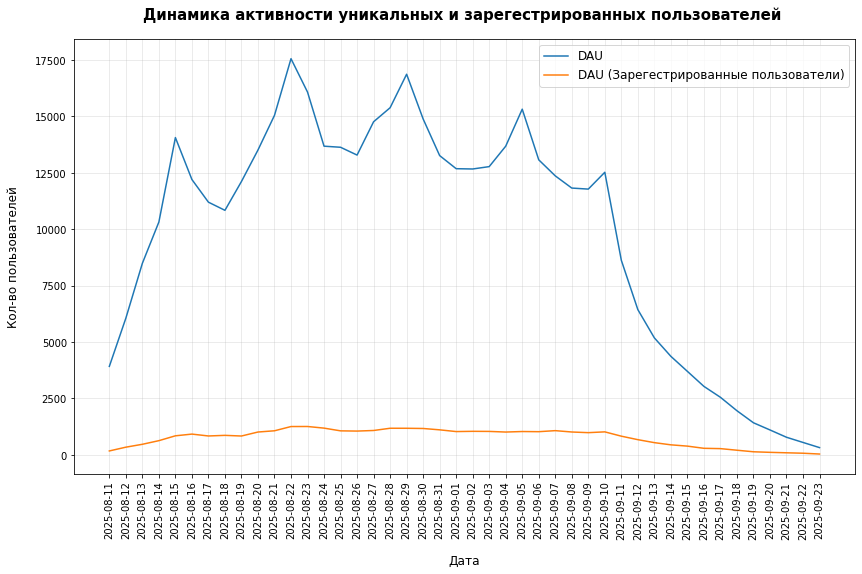

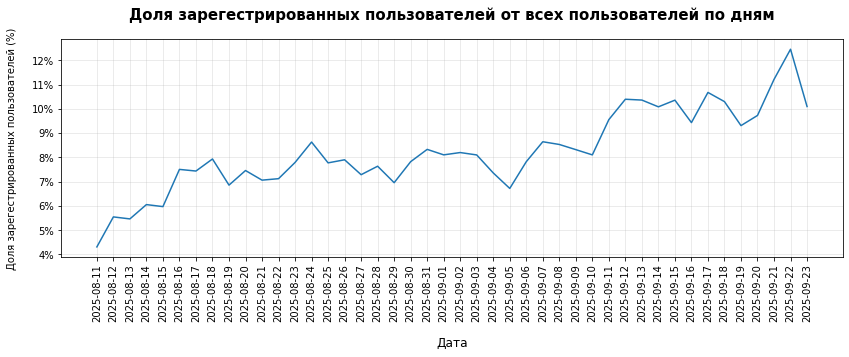

In [10]:
# Строим график пользователей в динамике
daily_users = sessions_history.groupby('session_date')['user_id'].count().reset_index().rename(columns={'user_id': 'dau'})
daily_reg_users = sessions_history[sessions_history['registration_flag'] == 1].groupby('session_date')['user_id'].count().reset_index().rename(columns={'user_id': 'dau_reg'})

merge_df = pd.merge(daily_users, daily_reg_users, how='inner', on='session_date')



plt.figure(figsize=(14, 8))
plt.plot(merge_df['session_date'], merge_df['dau'], label='DAU')
plt.plot(merge_df['session_date'], merge_df['dau_reg'], label='DAU (Зарегестрированные пользователи)')

plt.xticks(merge_df['session_date'], rotation=90)
plt.title('Динамика активности уникальных и зарегестрированных пользователей ', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Дата', fontsize=12, labelpad=15)
plt.ylabel('Кол-во пользователей', fontsize=12, labelpad=15)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)

plt.show()

# Строим граффик доли зарегестрированных пользователей по дням
merge_df['reg_share'] = merge_df['dau_reg']/merge_df['dau']

plt.figure(figsize=(14, 4))

plt.plot(merge_df['session_date'], merge_df['reg_share'])


plt.xticks(merge_df['session_date'], rotation=90)
plt.title('Доля зарегестрированных пользователей от всех пользователей по дням', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Дата', fontsize=12, labelpad=15)
plt.ylabel('Доля зарегестрированных пользователей (%)', fontsize=10, labelpad=15)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
plt.grid(True, alpha=0.3)

plt.show()

Вывод: 
Пик активности выпадает на числа, соответствующие дням конца недели(15 августа, 22 августа, 29 августа, 5 и 11 сентября, после чего наблюдается общий спад активности всех пользователей.
Доля зарегестрированных пользователей в период пика трафика составляла от 7-9%. С 10.09 она начала расти при общем падении активности.

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках задания проанализируйте число просмотренных страниц во время первых сессий пользователей. Найдите количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 8978 первых сессиях, две страницы — в 32 494 первых сессиях и так далее.

- Постройте столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

- На диаграмме должны быть заголовок, подписанные оси X и Y.

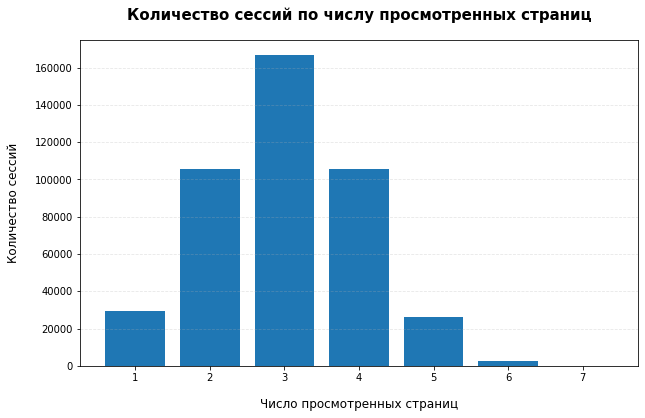

In [11]:
# Строим граффик распределения просмотренных страниц
page_count = sessions_history.groupby('page_counter')['user_id'].count().reset_index().rename(columns={'user_id': 'count_users'})

plt.figure(figsize=(10, 6))
plt.bar(page_count['page_counter'], page_count['count_users'])

plt.title('Количество сессий по числу просмотренных страниц', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Число просмотренных страниц', fontsize=12, labelpad=15)
plt.ylabel('Количество сессий', fontsize=12, labelpad=15)

plt.grid(axis='y', alpha=0.3, linestyle='--')

plt.show()

Вывод: В большинстве сессий просматриваются от двух до четырех страниц за сессию. 
В среднем 3 страницы - самый распространенный вариант

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Постройте график со средним значением доли успешных первых сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

In [12]:
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

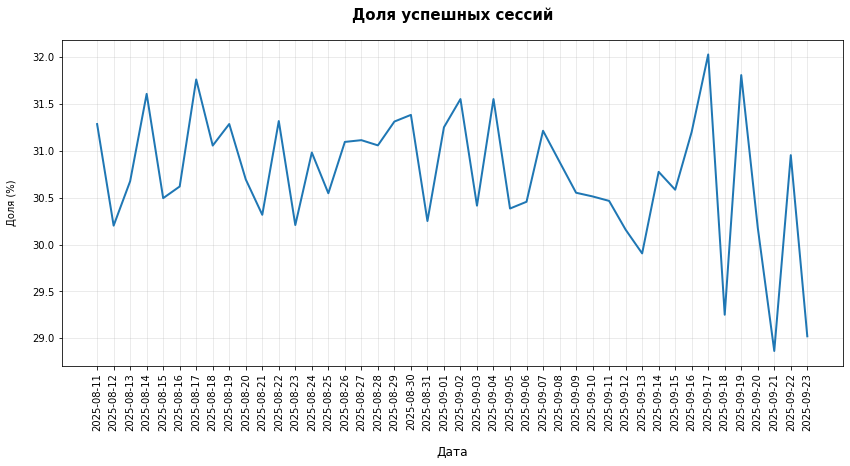

In [13]:


# Считаем общее число сессий и сумму good_session
daily_stats = (
    sessions_history
    .groupby('session_date')
    .agg(
        total_session=('session_id', 'count'),          
        sucess_session=('good_session', 'sum')          
    )
    .reset_index()
)

# Считаем долю в процентах
daily_stats['sucess_share'] = daily_stats['sucess_session'] / daily_stats['total_session'].replace(0)*100

# Строим график
plt.figure(figsize=(14, 6))
plt.plot(daily_stats['session_date'], daily_stats['sucess_share'], linewidth=2)

plt.xticks(daily_stats['session_date'], rotation=90)
plt.title('Доля успешных сессий', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Дата', fontsize=12, labelpad=15)
plt.ylabel('Доля (%)', fontsize=10, labelpad=15)


ax = plt.gca()

plt.grid(True, alpha=0.3)
plt.show()

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
В рамках курса вы уже рассчитывали размеры выборки и  использовали для этого онлайн-калькулятор. В этом задании предлагаем воспользоваться готовым кодом и рассчитать необходимое для вашего эксперимента количество пользователей.

Для этого установите в коде ниже следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%. Обратите внимание, что здесь нужно указать десятичную дробь, а не процент.

При расчёте размера выборки используйте метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

Запустите ячейку и изучите полученное значение.

In [14]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Задаём параметры
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03 * p  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Рассчитываем размер выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

Используйте данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитайте длительность теста, разделив одно на другое.

- Рассчитайте среднее количество уникальных пользователей приложения в день.

- Определите длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [15]:
from math import ceil

# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = avg_daily_users = sessions_history.groupby('session_date')['user_id'].nunique().mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(sample_size*2/avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.363636363636 пользователей в день составит 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

- Считайте и сохраните в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитайте количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитайте и выведите на экран процентную разницу в количестве пользователей в группах A и B. Постройте любую удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуйтесь формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [16]:
#Загружаем датафрейм и считаем кол-во уникальных юзеров в каждой группе
sessions_test_part = pd.read_csv('https://code.s3.yandex.net/datasets/sessions_project_test_part.csv')
group_info = sessions_test_part.groupby('test_group')['user_id'].nunique().reset_index().rename(columns={'user_id': 'users'})
group_info


,test_group,users
0,A,1477
1,B,1466


In [17]:
A = group_info[group_info["test_group"] == 'A']['users'].item()
B = group_info[group_info["test_group"] == 'B']['users'].item()
percent_diff = 100 * abs(A - B) / A
print(f"Процентная разница в количестве пользователей между группами: {round(percent_diff,2)}%")

Процентная разница в количестве пользователей между группами: 0.74%


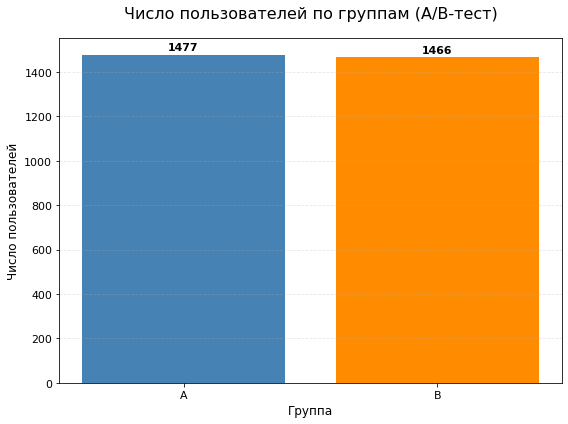

In [18]:
# строим график
plt.figure(figsize=(8, 6))
plt.bar(group_info['test_group'], group_info['users'], color=['steelblue', 'darkorange'])

plt.title('Число пользователей по группам (A/B-тест)', fontsize=16, pad=20)  
plt.xlabel('Группа', fontsize=12)
plt.ylabel('Число пользователей', fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

for i, v in enumerate(group_info['users']):
    plt.text(i, v + 10, str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитайте количество пользователей, которые встречаются одновременно в группах A и B, или убедитесь, что таких нет.

In [19]:
# Находим пользователей, у которых встречается более одного значения test_group
unique_counts = sessions_test_part.groupby('user_id')['test_group'].transform('nunique')

doubled_users = sessions_test_part[unique_counts > 1]['user_id'].nunique()
print(doubled_users)

0


#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Постройте две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение устройств в группах A и B.


In [20]:
# Сначала считаем уникальных пользователей по устройству и группе
device_ratio = (
    sessions_test_part
    .groupby(['test_group', 'device'])['user_id']
    .nunique()
    .reset_index()
)

# Теперь считаем сумму пользователей в каждой группе, чтобы найти долю
group_totals = device_ratio.groupby('test_group')['user_id'].transform('sum')

# Добавляем колонку с процентами
device_ratio['share %'] = round((device_ratio['user_id'] / group_totals) * 100, 2)

# Делаем сводную таблицу
pivot_share = device_ratio.pivot(index='device', columns='test_group', values='share %')

print(pivot_share)

test_group      A      B
device                  
Android     44.41  45.57
Mac         10.56  10.10
PC          24.98  25.99
iPhone      20.04  18.35


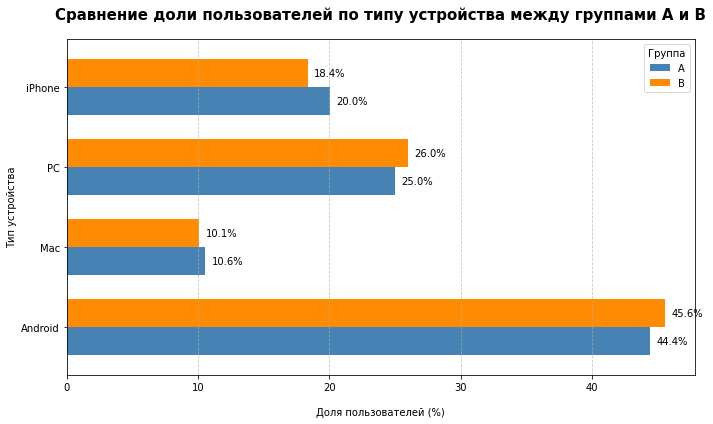

In [21]:
ax = pivot_share.plot(
    kind='barh', 
    figsize=(10, 6), 
    color=['steelblue', 'darkorange'],
    width=0.7
)

plt.title('Сравнение доли пользователей по типу устройства между группами A и B', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Доля пользователей (%)', labelpad=15)
plt.ylabel('Тип устройства')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend(title='Группа', loc='upper right')


for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 0.5, 
        p.get_y() + p.get_height() / 2, 
        f'{width:.1f}%', 
        va='center', 
        ha='left', 
        color='black', 
        fontsize=10
    )

plt.tight_layout()
plt.show()

Доля пользователей по группам примерно одинаковая, существенных различий нет, а значит тестирование даст нам довольно точный вывод

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

Постройте две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение регионов в группах A и B. Постарайтесь использовать другой тип диаграммы, не тот, что в прошлом задании.

In [22]:
# Сначала считаем уникальных пользователей по устройству и группе
region_ratio = (
    sessions_test_part
    .groupby(['test_group', 'region'])['user_id']
    .nunique()
    .reset_index()
)

group_totals = region_ratio.groupby('test_group')['user_id'].transform('sum')

# Добавляем колонку с процентами
region_ratio['share %'] = round((region_ratio['user_id'] / group_totals) * 100, 2)

pivot_share = region_ratio.pivot(index='region', columns='test_group', values='share %')

print(pivot_share)

test_group      A     B
region                 
CIS         43.60  44.0
EU          15.17  14.8
MENA        41.23  41.2


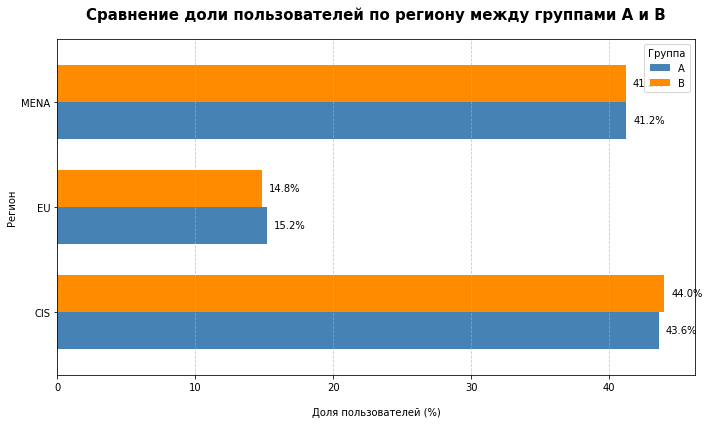

In [23]:
ax = pivot_share.plot(
    kind='barh', 
    figsize=(10, 6), 
    color=['steelblue', 'darkorange'],
    width=0.7
)

plt.title('Сравнение доли пользователей по региону между группами A и B', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Доля пользователей (%)', labelpad=15)
plt.ylabel('Регион')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend(title='Группа', loc='upper right')


for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 0.5, 
        p.get_y() + p.get_height() / 2, 
        f'{width:.1f}%', 
        va='center', 
        ha='left', 
        color='black', 
        fontsize=10
    )

plt.tight_layout()
plt.show()

Соотношение по региону тоже плюс-минус равное

#### 3.5. Вывод после проверки A/B-теста

На основе проведённого анализа A/B-теста сформулируйте и запишите свои выводы. В выводе обязательно укажите:

- Было ли обнаружено различие в количестве пользователей в двух группах.

- Являются ли выборки независимыми. Было ли обнаружено пересечение пользователей из тестовой и контрольной групп.

- Сохраняется ли равномерное распределение пользователей тестовой и контрольной групп по категориальным переменным: устройствам и регионам.

Сделайте заключение: корректно ли проходит A/B-тест, или наблюдаются какие-либо нарушения.

Вывод:
* Различие между группами минимально. Группы сопоставимы по размеру.
* Доля пользователей между группами по региону и платформе также несущественно.
* Так что  тест проходит корректно, а его результаты не будут искажены

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считайте и сохраните в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [24]:
sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

sessions_test.sample(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
1695,F75397BA04BAB791,56C646D545AF96DE,2025-10-17,2025-10-17 20:59:24,2025-10-17,1,0,3,MENA,Android,A,0
9337,A41E9A8C5A3D106E,6B0728A5659ACF68,2025-10-16,2025-10-16 22:43:46,2025-10-16,1,0,4,MENA,iPhone,A,1
44556,BA175CE292C5BA1F,8D1B55A283CD81CF,2025-10-25,2025-10-25 23:09:24,2025-10-16,3,0,4,MENA,PC,B,1
66668,865ACEA4CB731B95,1439E58E7AA5B067,2025-11-01,2025-11-01 17:37:48,2025-10-19,3,0,3,EU,PC,B,0
8646,28EBE6E62E5DB835,77E85C4CEFDEA7CC,2025-10-17,2025-10-17 12:46:02,2025-10-16,2,0,4,MENA,iPhone,B,1


In [25]:
unique_users = sessions_test.groupby('test_group')['user_id'].nunique()
print(unique_users)

test_group
A    15163
B    15416
Name: user_id, dtype: int64


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Подумайте, о какой метрике идёт речь и как она будет учтена в формулировке гипотез. Сформулируйте нулевую и альтернативную гипотезы.

Не забывайте, что до проведения эксперимента важно выделять и отслеживать изменение прокси- и барьерных метрик. В имеющихся у вас данных о проведении эксперимента этих метрик нет. Подумайте, какие показатели вы бы выбрали в качестве прокси- и барьерных метрик, если бы проводили этот эксперимент самостоятельно.

* **Нулевая гипотеза ($H_0$):** Новый алгоритм рекомендаций не влияет на долю успешных первых сессий. Доли успешных первых сессий в контрольной (A) и тестовой (B) группах равны:

$$p_A = p_B$$


* **Альтернативная гипотеза ($H_1$):** Новый алгоритм рекомендаций влияет на вовлечение: доля успешных первых сессий в группах различается (двусторонний тест, $p_A \neq p_B$) или статистически значимо выше в тестовой группе B (односторонний тест, $p_B > p_A$).

#### 4.3. Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используйте созданный на первом шаге задания столбец `good_session` и рассчитайте долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразите на экране.

In [26]:
#  Считаем суммарное кол-во сессий по группам
summ = sessions_test.groupby('test_group').agg(
    total_sessions=('session_id', 'count'),
    good_sessions=('good_session', 'sum')
)

# Считаем долю
summ['good_session_rate'] = summ['good_sessions'] / summ['total_sessions']

# Считаем разницу по именам групп
rate_diff = summ.loc['A', 'good_session_rate'] - summ.loc['B', 'good_session_rate']

print(summ)
print(f'Разница в доле успешных сессий между группами: {rate_diff:.3f}')

            total_sessions  good_sessions  good_session_rate
test_group                                                  
A                    49551          15248           0.307723
B                    50454          16059           0.318290
Разница в доле успешных сессий между группами: -0.011


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге вы убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитайте, является ли изменение в метрике доли успешных первых сессий статистически значимым.

- Выведите на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [27]:
from statsmodels.stats.proportion import proportions_ztest

count_A = summ.loc['A', 'good_sessions']
count_B = summ.loc['B', 'good_sessions']
nobs_A = summ.loc['A', 'total_sessions']
nobs_B = summ.loc['B', 'total_sessions']


successes = [count_A, count_B]
totals = [nobs_A, nobs_B]

alpha = 0.05

# Проводим Z-тест
z_stat, p_value = proportions_ztest(successes, totals, alternative='two-sided')

print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.7f}")

if p_value < alpha:
    print("✅ Вывод: Нулевая гипотеза отвергается. Разница статистически значима!")
    
    if count_A / nobs_A > count_B / nobs_B:
        print("   Группа A показала лучший результат.")
    else:
        print("   Группа B показала лучший результат.")
else:
    print("❌ Вывод: Нулевая гипотеза не отвергается. Статистически значимых различий не обнаружено.")

Z-статистика: -3.6027
p-value: 0.0003149
✅ Вывод: Нулевая гипотеза отвергается. Разница статистически значима!
   Группа B показала лучший результат.


#### 4.5. Вывод по результатам A/B-эксперимента

На основе проведённого анализа результатов теста сформулируйте и запишите свои выводы для команды разработки приложения. В выводе обязательно укажите:

- Характеристики проведённого эксперимента, количество задействованных пользователей и длительность эксперимента.

- Повлияло ли внедрение нового алгоритма рекомендаций на рост ключевой метрики и как.

- Каким получилось значение p-value для оценки статистической значимости выявленного эффекта.

- Стоит ли внедрять нововведение в приложение.

Выводы по результатам A/B-теста эксперимента

Было рассмотрено две группы пользователей:
* Группа A (контрольная): 15163 пользователей.
* Группа B (тестовая): 15416 пользователей.
Считали по метрике успешных сессий, где page_counter ≥ 4

По результатам двадцатидневного эксперимента у нас имееются следующие показатели:
* Группа A (без нововведений): 30.77% успешных сессий (15248 из 49551).
* Группа B (введен новый алгоритм): 31.83% успешных сессий (16059 из 50454).
* Общий прирост составляет +1.06%.

p-value по результатам z-теста равен 0.0003 .
Разница статистически значима (p < 0.05)
Новый алгоритм показал положительный прирост доли успешных сессий, что говорит о его эффективности в удержании пользователей.

Можно внедрять нововведение в приложение, т.к. мы зафиксировали стабильный прирост длительности сессий, есть статистически значимый прирост ключевой метрики.
